# High Frequency Words in Jane Austen’s Emma
**Sachi Kapoor | DATA 620**

This notebook examines word frequencies in Jane Austen’s *Emma*
using the NLTK Gutenberg corpus. I identify the most common words,
calculate their relative frequencies, and examine whether the
distribution follows Zipf’s law.

In [1]:
import nltk
from nltk.corpus import gutenberg
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt

nltk.download("gutenberg")

# Load the novel and keep alphabetic words in lowercase.
tokens = gutenberg.words("austen-emma.txt")
words = [token.lower() for token in tokens if token.isalpha()]

word_counts = Counter(words)

print(f"Total words: {len(words):,}")
print(f"Unique words: {len(word_counts):,}")

Total words: 161,600
Unique words: 7,079


[nltk_data] Downloading package gutenberg to
[nltk_data]     /home/63d9b475-c6e3-435b-94ab-
[nltk_data]     2620ffaadab5/nltk_data...
[nltk_data]   Package gutenberg is already up-to-date!


## Unique Words and Text Preparation

After converting words to lowercase and keeping only alphabetic
tokens, the corpus contains 161,600 total words and 7,079 unique
words. Different grammatical forms are counted separately, while
capitalization does not create a new word. Common words are retained
because they are important to the word-frequency distribution.

## Words Accounting for Half of the Corpus

The following calculation ranks words by frequency and finds the
smallest number of distinct words whose combined counts reach at
least 50% of all word occurrences.

In [2]:
# Sort all unique words from most to least frequent.
ranked_words = word_counts.most_common()

cumulative_count = 0
halfway_word_count = 0

for word, count in ranked_words:
    cumulative_count += count
    halfway_word_count += 1

    if cumulative_count >= len(words) / 2:
        break

coverage = cumulative_count / len(words)

print(f"Half of all word occurrences: {len(words) / 2:,.0f}")
print(f"Unique words needed to reach half: {halfway_word_count:,}")
print(f"Combined occurrences of these words: {cumulative_count:,}")
print(f"Share of the corpus covered: {coverage:.2%}")

Half of all word occurrences: 80,800
Unique words needed to reach half: 56
Combined occurrences of these words: 80,891
Share of the corpus covered: 50.06%


The 56 most frequent words account for 80,891 occurrences, or
50.06% of the corpus. This shows that a small portion of the
novel’s vocabulary makes up more than half of its word occurrences.

## The 200 Most Frequent Words

The table below lists the 200 most frequent words, ranked by count.
Relative frequency is calculated by dividing each word’s count by
the total number of words in the corpus.

In [3]:
# Create the top-200 word frequency table.
top_200 = pd.DataFrame(
    word_counts.most_common(200),
    columns=["Word", "Count"]
)

top_200.insert(0, "Rank", range(1, len(top_200) + 1))
top_200["Relative Frequency"] = top_200["Count"] / len(words)
top_200["Percentage"] = top_200["Relative Frequency"] * 100

# Display all 200 rows without changing global display settings.
with pd.option_context("display.max_rows", 200):
    display(
        top_200.style.format({
            "Relative Frequency": "{:.6f}",
            "Percentage": "{:.3f}%"
        }).hide(axis="index")
    )

Rank,Word,Count,Relative Frequency,Percentage
1,to,5239,0.032420,3.242%
2,the,5201,0.032184,3.218%
3,and,4896,0.030297,3.030%
4,of,4291,0.026553,2.655%
5,i,3178,0.019666,1.967%
6,a,3129,0.019363,1.936%
7,it,2528,0.015644,1.564%
8,her,2469,0.015278,1.528%
9,was,2398,0.014839,1.484%
10,she,2340,0.014480,1.448%


## Relative Frequency of the 200 Most Common Words

This graph shows each word’s share of all word occurrences in the
corpus. Words are ranked from most to least frequent, with rank 1
representing the most common word.

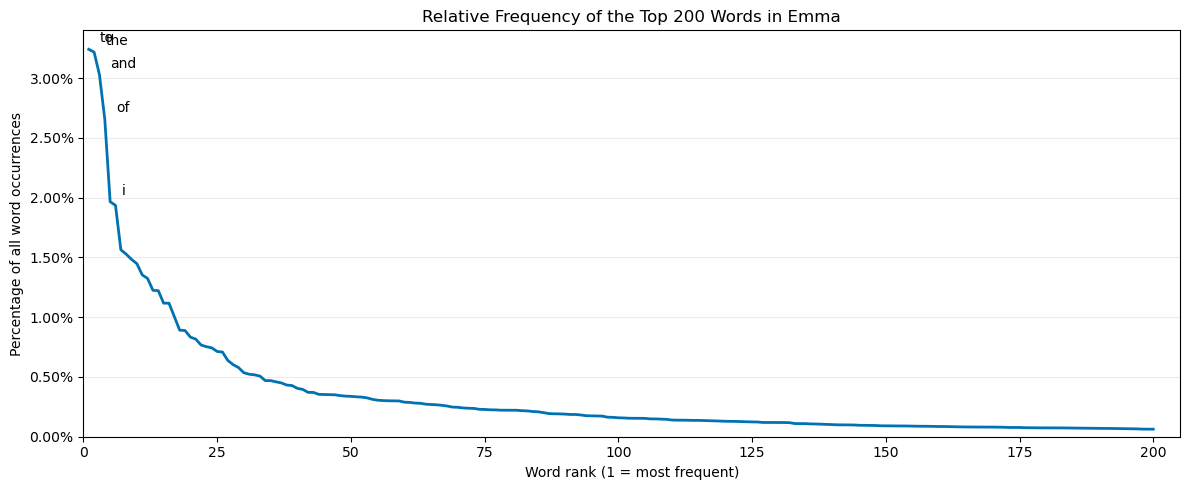

In [4]:
from matplotlib.ticker import PercentFormatter

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    top_200["Rank"],
    top_200["Relative Frequency"],
    color="#0072B2",
    linewidth=2
)

# Label the five most frequent words.
for _, row in top_200.head(5).iterrows():
    ax.annotate(
        row["Word"],
        (row["Rank"], row["Relative Frequency"]),
        xytext=(8, 5),
        textcoords="offset points",
        fontsize=10
    )

ax.set_title("Relative Frequency of the Top 200 Words in Emma")
ax.set_xlabel("Word rank (1 = most frequent)")
ax.set_ylabel("Percentage of all word occurrences")
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.set_xlim(0, 205)
ax.set_ylim(bottom=0)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

## Comparison with Zipf’s Law

Zipf’s law predicts that a word’s frequency is approximately
inversely proportional to its rank: frequency ∝ 1/rank.

On a graph with logarithmic scales on both axes, this relationship
would appear as a straight line with a slope of -1. I compare
the top 200 observed frequencies with a 1/rank reference line
and calculate their log-log slope.

The reference line is scaled to match the most frequent word.
This is a descriptive comparison, rather than a formal statistical
test of Zipf’s law.

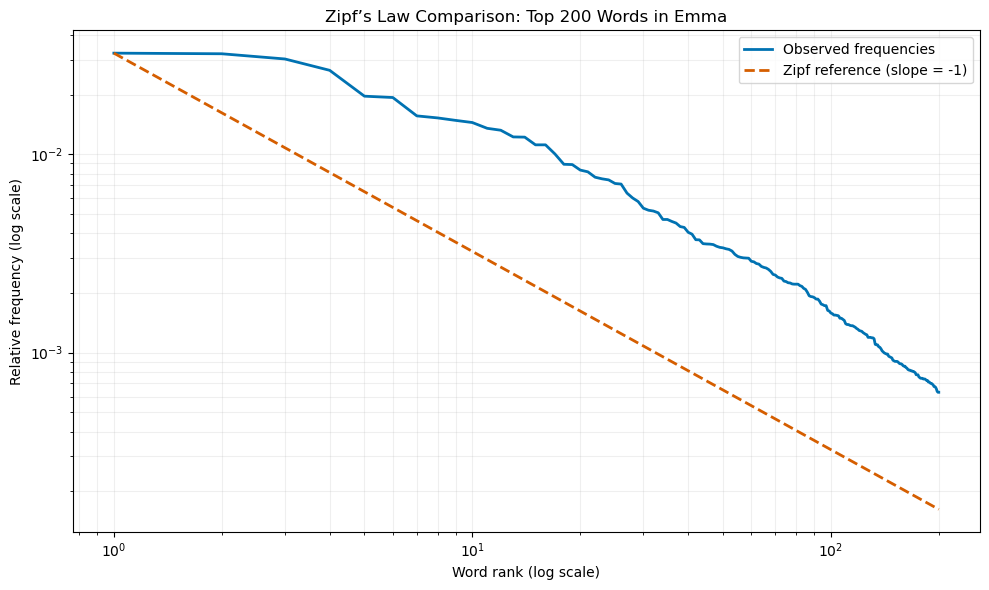

Observed log-log slope: -0.964
Zipf’s law reference slope: -1.000


In [5]:
import numpy as np

ranks = top_200["Rank"].to_numpy()
frequencies = top_200["Relative Frequency"].to_numpy()

# Zipf reference, anchored to the most frequent word.
zipf_reference = frequencies[0] / ranks

# Fit a straight line to log-transformed ranks and frequencies.
slope, intercept = np.polyfit(
    np.log10(ranks),
    np.log10(frequencies),
    1
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.loglog(
    ranks, frequencies,
    color="#0072B2", linewidth=2,
    label="Observed frequencies"
)

ax.loglog(
    ranks, zipf_reference,
    color="#D55E00", linestyle="--", linewidth=2,
    label="Zipf reference (slope = -1)"
)

ax.set_title("Zipf’s Law Comparison: Top 200 Words in Emma")
ax.set_xlabel("Word rank (log scale)")
ax.set_ylabel("Relative frequency (log scale)")
ax.grid(True, which="both", alpha=0.2)
ax.legend()

plt.tight_layout()
plt.show()

print(f"Observed log-log slope: {slope:.3f}")
print("Zipf’s law reference slope: -1.000")

## Does the Distribution Follow Zipf’s Law?

The top 200 words show an approximate Zipf-like pattern. Their
observed log-log slope is -0.964, which is close to the theoretical
slope of -1. This suggests that word frequency generally decreases
roughly in proportion to the inverse of rank.

However, the observed curve is not perfectly straight, especially
among the highest-ranked words. It also does not overlap the
reference line, which was anchored to the most frequent word rather
than fitted to the data. The slope supports an approximate relationship,
but it does not prove an exact fit. This comparison applies only to
the top 200 words, not the entire vocabulary.

## How Does This Corpus Differ from Other Corpora?

Emma represents one author, one literary genre, and a particular
historical setting. I would expect character names such as Emma
and terms related to social relationships to occur more frequently
here than in a broad collection of texts.

Austen’s writing style and the novel’s dialogue also influence word
choice. A corpus of scientific articles would likely contain more
technical vocabulary, while modern social media would include more
slang and references to technology.

Common grammatical words may appear frequently across many English
corpora, but their rankings and proportions can still vary. There
is no single available collection representing “all words in all
corpora,” so these comparisons are expectations rather than findings
from a direct analysis of another dataset.

The processing choices also affect the results. Lowercasing combines
capitalized and lowercase forms, while keeping only alphabetic tokens
excludes punctuation and numbers. The tokenizer can split contractions
and hyphenated expressions into separate tokens.

## Conclusion

The processed corpus contains 161,600 word occurrences and 7,079
unique words. Only 56 distinct words account for 50.06% of all
occurrences, showing how strongly usage is concentrated among common
words. The top 200 words display an approximate Zipf-like pattern,
although their frequencies also reflect the novel’s style and content.

## Data Source

Jane Austen’s Emma, accessed through the NLTK Gutenberg corpus
using the file austen-emma.txt.